In [1]:

# ============================================================
# BLOCK 1: IMPORT LIBRARIES, LOAD DATASET AND PREPROCESSING
# START: BLOCK 1
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import FactorAnalysis

from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

from scipy.cluster.hierarchy import dendrogram, linkage

# Load the unlabelled dataset
from google.colab import files

uploaded = files.upload()

file_name = list(uploaded.keys())[0]
df = pd.read_csv(file_name)

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

print("\nFirst 5 Records:")
display(df.head())

print("\nDataset Information:")
df.info()

# Remove student ID from numerical features
X = df.drop(columns=['Student_ID'], errors='ignore')

# Select numerical columns
X = X.select_dtypes(include=np.number)

# Handle missing values
X = X.fillna(X.median())

# Standardize numerical features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("\nOriginal Features:", X.shape[1])
print("Total Records:", X.shape[0])
print("Missing Values:", X.isnull().sum().sum())
print("Scaled Data Shape:", X_scaled.shape)

print("\nPreprocessing completed successfully!")

# ============================================================
# END: BLOCK 1
# ============================================================


Saving Unlabelled_Student_Assessment_Clustering_5000.csv to Unlabelled_Student_Assessment_Clustering_5000.csv
Dataset loaded successfully!
Dataset Shape: (5000, 15)

First 5 Records:


,Student_ID,Study_Hours_Per_Week,Assignment_Submissions,Assignment_Average_Score,Quiz_Attempts,Quiz_Average_Score,Attendance_Percent,Late_Submissions,Forum_Interactions,Practice_Activities,LMS_Login_Frequency,Video_Learning_Hours,Resource_Downloads,Peer_Discussion_Posts,Self_Assessment_Attempts
0,STU00001,13.14,6,60.48,20,84.14,78.73,1,14,15,16,13.00,22,5,8
1,STU00002,9.27,7,65.00,10,77.94,78.24,6,8,14,22,9.32,10,6,4
2,STU00003,14.28,9,77.11,16,83.26,95.18,3,4,32,23,8.41,12,4,8
3,STU00004,23.11,7,84.90,22,80.35,95.36,0,17,37,38,14.16,32,10,9
4,STU00005,8.79,11,82.16,15,53.84,70.49,6,9,9,16,2.43,24,4,7



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 15 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Student_ID                5000 non-null   object 
 1   Study_Hours_Per_Week      5000 non-null   float64
 2   Assignment_Submissions    5000 non-null   int64  
 3   Assignment_Average_Score  5000 non-null   float64
 4   Quiz_Attempts             5000 non-null   int64  
 5   Quiz_Average_Score        5000 non-null   float64
 6   Attendance_Percent        5000 non-null   float64
 7   Late_Submissions          5000 non-null   int64  
 8   Forum_Interactions        5000 non-null   int64  
 9   Practice_Activities       5000 non-null   int64  
 10  LMS_Login_Frequency       5000 non-null   int64  
 11  Video_Learning_Hours      5000 non-null   float64
 12  Resource_Downloads        5000 non-null   int64  
 13  Peer_Discussion_Posts     5000 non-null  

K-MEANS RESULTS


,K,Inertia,Silhouette Score,Iterations
0,2,42949.795196,0.350660,4
1,3,35490.858051,0.220452,7
2,4,32501.066276,0.155609,10
3,5,30602.455531,0.140904,45
4,6,29179.665712,0.122149,19


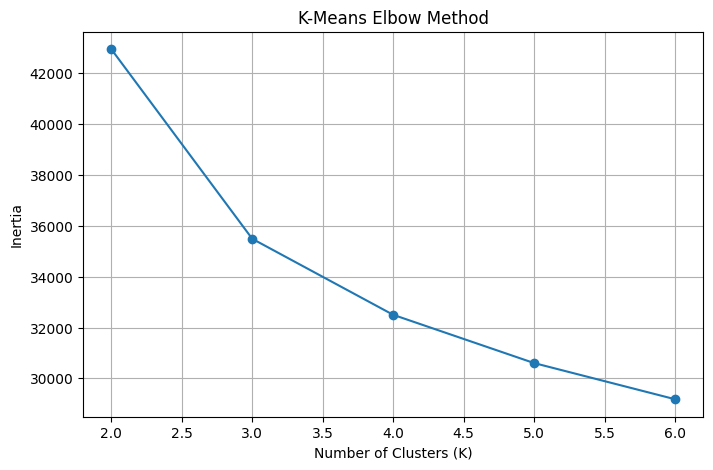

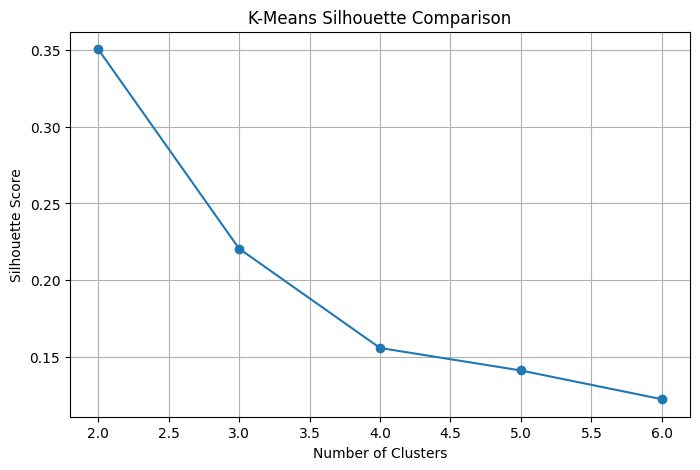


Final Cluster Distribution:
KMeans_Cluster
0    1897
1    2496
2     607
Name: count, dtype: int64

Cluster Centers:


,Study_Hours_Per_Week,Assignment_Submissions,Assignment_Average_Score,Quiz_Attempts,Quiz_Average_Score,Attendance_Percent,Late_Submissions,Forum_Interactions,Practice_Activities,LMS_Login_Frequency,Video_Learning_Hours,Resource_Downloads,Peer_Discussion_Posts,Self_Assessment_Attempts
0,13.402216,7.570526,81.031679,14.181053,77.100389,81.006779,3.611053,13.102105,17.537895,23.204737,8.468926,22.044737,5.923684,7.410526
1,6.944645,7.301645,68.406879,9.048135,58.633065,69.211256,5.432812,7.399118,9.985560,15.141596,4.789346,12.575211,3.367429,4.649819
2,24.724283,7.408567,93.830329,22.568369,96.458138,95.388056,1.434926,22.311367,30.556837,36.841845,14.792932,37.995058,9.932455,11.756178


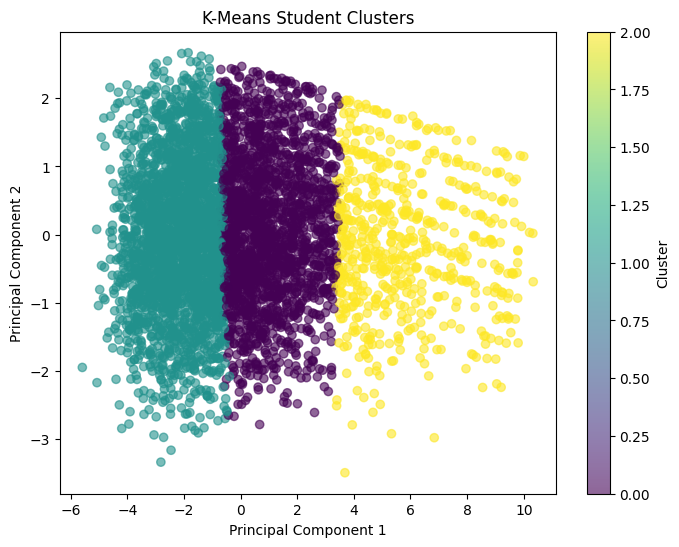

In [2]:

# ============================================================
# BLOCK 2: K-MEANS CLUSTERING
# ============================================================

k_values = [2, 3, 4, 5, 6]

results = []

for k in k_values:

    kmeans = KMeans(
        n_clusters=k,
        init='k-means++',
        n_init=10,
        max_iter=300,
        random_state=42
    )

    labels = kmeans.fit_predict(X_scaled)

    inertia = kmeans.inertia_
    silhouette = silhouette_score(X_scaled, labels)

    results.append({
        'K': k,
        'Inertia': inertia,
        'Silhouette Score': silhouette,
        'Iterations': kmeans.n_iter_
    })

results_df = pd.DataFrame(results)

print("K-MEANS RESULTS")
display(results_df)

# Elbow Method
plt.figure(figsize=(8, 5))
plt.plot(
    results_df['K'],
    results_df['Inertia'],
    marker='o'
)
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("K-Means Elbow Method")
plt.grid()
plt.show()

# Silhouette comparison
plt.figure(figsize=(8, 5))
plt.plot(
    results_df['K'],
    results_df['Silhouette Score'],
    marker='o'
)
plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Score")
plt.title("K-Means Silhouette Comparison")
plt.grid()
plt.show()

# Final model with K=3
kmeans_final = KMeans(
    n_clusters=3,
    init='k-means++',
    n_init=20,
    max_iter=500,
    random_state=42
)

df['KMeans_Cluster'] = kmeans_final.fit_predict(X_scaled)

print("\nFinal Cluster Distribution:")
print(df['KMeans_Cluster'].value_counts().sort_index())

print("\nCluster Centers:")
display(pd.DataFrame(
    scaler.inverse_transform(kmeans_final.cluster_centers_),
    columns=X.columns
))

# Visualize using PCA
pca_plot = PCA(n_components=2)
X_2d = pca_plot.fit_transform(X_scaled)

plt.figure(figsize=(8, 6))
plt.scatter(
    X_2d[:, 0],
    X_2d[:, 1],
    c=df['KMeans_Cluster'],
    cmap='viridis',
    alpha=0.6
)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("K-Means Student Clusters")
plt.colorbar(label="Cluster")
plt.show()

# ============================================================
# END: BLOCK 2
# ============================================================


GMM COMPONENT COMPARISON


,Components,AIC,BIC,Log Likelihood,Silhouette Score
0,2,137061.917951,138619.527123,-13.658392,0.394673
1,3,136519.609060,138859.281416,-13.580161,0.200812
2,4,136453.638259,139575.373798,-13.549564,0.123057
3,5,136435.801277,140339.599998,-13.523780,0.109908



COVARIANCE TYPE COMPARISON


,Covariance Type,AIC,BIC,Log Likelihood
0,full,136519.609060,138859.281416,-13.580161
1,tied,142053.667525,143024.729311,-14.175567
2,diag,154027.178455,154587.657070,-15.385518
3,spherical,160173.795174,160480.103254,-16.007980



GMM CLUSTER DISTRIBUTION:
GMM_Cluster
0    2040
1    2537
2     423
Name: count, dtype: int64

First 10 Student Membership Probabilities:


,Cluster_0,Cluster_1,Cluster_2
0,0.916062,8.393779e-02,0.0
1,0.166423,8.335770e-01,0.0
2,0.950775,4.922451e-02,0.0
3,1.000000,1.244562e-08,0.0
4,0.130817,8.691835e-01,0.0
5,0.172546,8.274535e-01,0.0
6,1.000000,9.449094e-10,0.0
7,0.991316,8.683843e-03,0.0
8,0.040411,9.595893e-01,0.0
9,0.914707,8.529282e-02,0.0



Final GMM AIC: 136519.6090601434
Final GMM BIC: 138859.28141586183
Final GMM Average Log Likelihood: -13.580160906014342


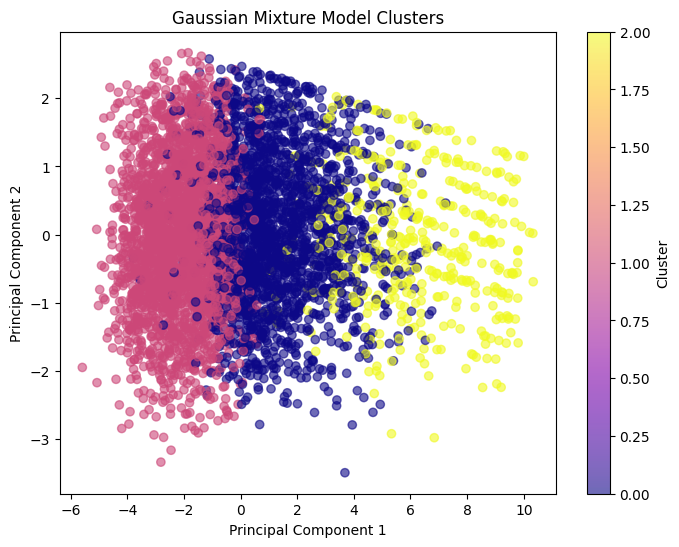

In [3]:

# ============================================================
# BLOCK 3: GAUSSIAN MIXTURE MODEL (GMM)
# ============================================================

# Test different numbers of Gaussian components
gmm_results = []

for k in [2, 3, 4, 5]:

    gmm = GaussianMixture(
        n_components=k,
        covariance_type='full',
        max_iter=200,
        n_init=3,
        reg_covar=1e-6,
        random_state=42
    )

    gmm.fit(X_scaled)

    labels = gmm.predict(X_scaled)

    gmm_results.append({
        'Components': k,
        'AIC': gmm.aic(X_scaled),
        'BIC': gmm.bic(X_scaled),
        'Log Likelihood': gmm.score(X_scaled),
        'Silhouette Score': silhouette_score(X_scaled, labels)
    })

gmm_results_df = pd.DataFrame(gmm_results)

print("GMM COMPONENT COMPARISON")
display(gmm_results_df)

# Compare covariance types
covariance_results = []

for cov in ['full', 'tied', 'diag', 'spherical']:

    model = GaussianMixture(
        n_components=3,
        covariance_type=cov,
        max_iter=200,
        n_init=3,
        random_state=42
    )

    model.fit(X_scaled)
    labels = model.predict(X_scaled)

    covariance_results.append({
        'Covariance Type': cov,
        'AIC': model.aic(X_scaled),
        'BIC': model.bic(X_scaled),
        'Log Likelihood': model.score(X_scaled)
    })

print("\nCOVARIANCE TYPE COMPARISON")
display(pd.DataFrame(covariance_results))

# Train final GMM model
gmm_final = GaussianMixture(
    n_components=3,
    covariance_type='full',
    max_iter=200,
    n_init=5,
    random_state=42
)

gmm_final.fit(X_scaled)

gmm_labels = gmm_final.predict(X_scaled)

# Assign cluster labels
df['GMM_Cluster'] = gmm_labels

# Calculate membership probabilities
probabilities = gmm_final.predict_proba(X_scaled)

print("\nGMM CLUSTER DISTRIBUTION:")
print(df['GMM_Cluster'].value_counts().sort_index())

print("\nFirst 10 Student Membership Probabilities:")
display(pd.DataFrame(
    probabilities[:10],
    columns=['Cluster_0', 'Cluster_1', 'Cluster_2']
))

print("\nFinal GMM AIC:", gmm_final.aic(X_scaled))
print("Final GMM BIC:", gmm_final.bic(X_scaled))
print("Final GMM Average Log Likelihood:", gmm_final.score(X_scaled))

# Visualize GMM clusters
plt.figure(figsize=(8, 6))
plt.scatter(
    X_2d[:, 0],
    X_2d[:, 1],
    c=gmm_labels,
    cmap='plasma',
    alpha=0.6
)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Gaussian Mixture Model Clusters")
plt.colorbar(label="Cluster")
plt.show()

# ============================================================
# END: BLOCK 3
# ============================================================


MANUAL EM RESULTS
Number of Iterations: 100
Final Log Likelihood: -8641.29921487695

Component Weights:
[0.0853243 0.9146757]

Component Means:
[[ 2.20954516  1.77490136]
 [-0.20611446 -0.16556929]]

Cluster Distribution:
0     427
1    4573
Name: count, dtype: int64


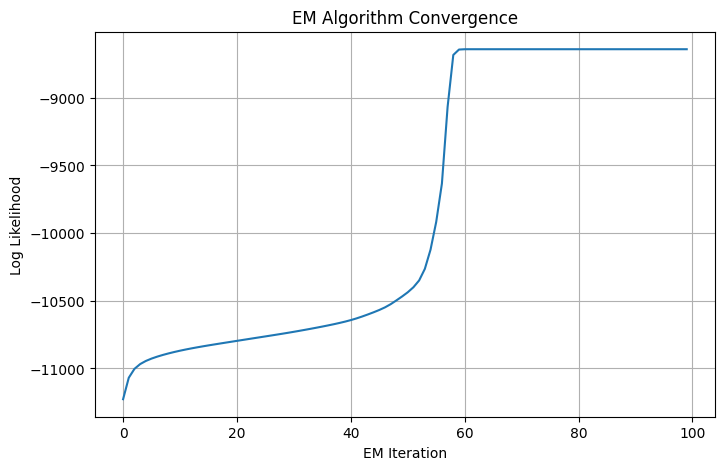

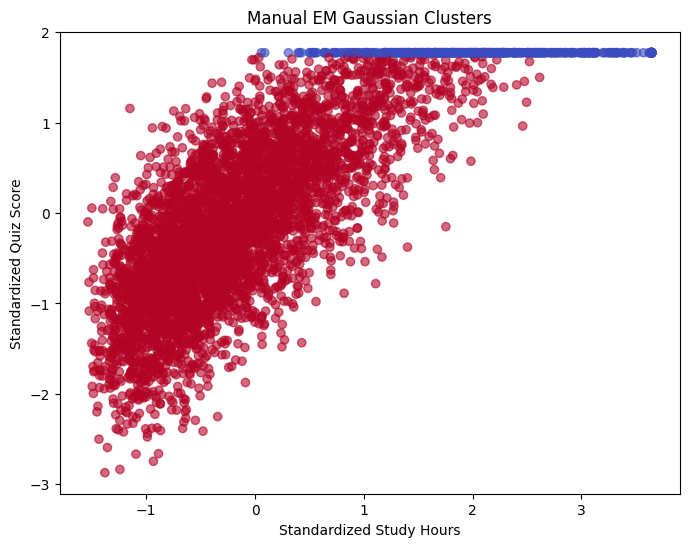

In [4]:

# ============================================================
# BLOCK 4: ALTERNATIVE VIEW OF EM
# MANUAL EXPECTATION MAXIMIZATION IMPLEMENTATION
# ============================================================

from scipy.stats import multivariate_normal

# Use two features for a clear EM demonstration
em_features = ['Study_Hours_Per_Week', 'Quiz_Average_Score']

X_em = StandardScaler().fit_transform(
    df[em_features].values
)

# Initialize parameters
np.random.seed(42)

n, d = X_em.shape
K = 2

weights = np.array([0.5, 0.5])

means = X_em[np.random.choice(n, K, replace=False)]

covariances = np.array([
    np.eye(d),
    np.eye(d)
])

log_likelihood_history = []

# EM iterations
for iteration in range(100):

    # ---------------- E-STEP ----------------
    responsibilities = np.zeros((n, K))

    for k in range(K):

        responsibilities[:, k] = (
            weights[k] *
            multivariate_normal.pdf(
                X_em,
                mean=means[k],
                cov=covariances[k],
                allow_singular=True
            )
        )

    # Normalize responsibilities
    responsibilities_sum = responsibilities.sum(
        axis=1, keepdims=True
    )

    responsibilities /= np.maximum(
        responsibilities_sum, 1e-300
    )

    # ---------------- M-STEP ----------------
    Nk = responsibilities.sum(axis=0)

    weights = Nk / n

    for k in range(K):

        means[k] = np.sum(
            responsibilities[:, k, None] * X_em,
            axis=0
        ) / Nk[k]

        diff = X_em - means[k]

        covariances[k] = (
            (responsibilities[:, k, None] * diff).T
            @ diff
        ) / Nk[k]

        covariances[k] += np.eye(d) * 1e-6

    # Calculate log likelihood
    likelihood = np.zeros((n, K))

    for k in range(K):

        likelihood[:, k] = (
            weights[k] *
            multivariate_normal.pdf(
                X_em,
                mean=means[k],
                cov=covariances[k],
                allow_singular=True
            )
        )

    total_likelihood = np.sum(
        np.log(np.maximum(likelihood.sum(axis=1), 1e-300))
    )

    log_likelihood_history.append(total_likelihood)

# Final cluster assignments
em_labels = np.argmax(responsibilities, axis=1)

df['EM_Cluster'] = em_labels

print("MANUAL EM RESULTS")
print("Number of Iterations:", len(log_likelihood_history))
print("Final Log Likelihood:", log_likelihood_history[-1])

print("\nComponent Weights:")
print(weights)

print("\nComponent Means:")
print(means)

print("\nCluster Distribution:")
print(pd.Series(em_labels).value_counts().sort_index())

# Plot likelihood convergence
plt.figure(figsize=(8, 5))
plt.plot(log_likelihood_history)
plt.xlabel("EM Iteration")
plt.ylabel("Log Likelihood")
plt.title("EM Algorithm Convergence")
plt.grid()
plt.show()

# Plot student clusters
plt.figure(figsize=(8, 6))
plt.scatter(
    X_em[:, 0],
    X_em[:, 1],
    c=em_labels,
    cmap='coolwarm',
    alpha=0.6
)
plt.xlabel("Standardized Study Hours")
plt.ylabel("Standardized Quiz Score")
plt.title("Manual EM Gaussian Clusters")
plt.show()

# ============================================================
# END: BLOCK 4
# ============================================================


FACTOR ANALYSIS COMPARISON


,Number of Factors,Log Likelihood,Iterations
0,2,-14.400826,35
1,3,-14.378301,16
2,4,-14.362576,287
3,5,-14.361034,273



Factor Scores Shape: (5000, 3)

FACTOR LOADINGS:


,Factor 1,Factor 2,Factor 3
Study_Hours_Per_Week,0.992,0.016,-0.018
Assignment_Submissions,0.010,-0.675,-0.001
Assignment_Average_Score,0.675,-0.524,-0.014
Quiz_Attempts,0.857,0.024,0.201
Quiz_Average_Score,0.799,-0.019,0.304
Attendance_Percent,0.724,-0.004,0.010
Late_Submissions,-0.544,0.009,-0.032
Forum_Interactions,0.738,0.010,-0.050
Practice_Activities,0.777,0.002,-0.038
LMS_Login_Frequency,0.840,0.026,-0.040


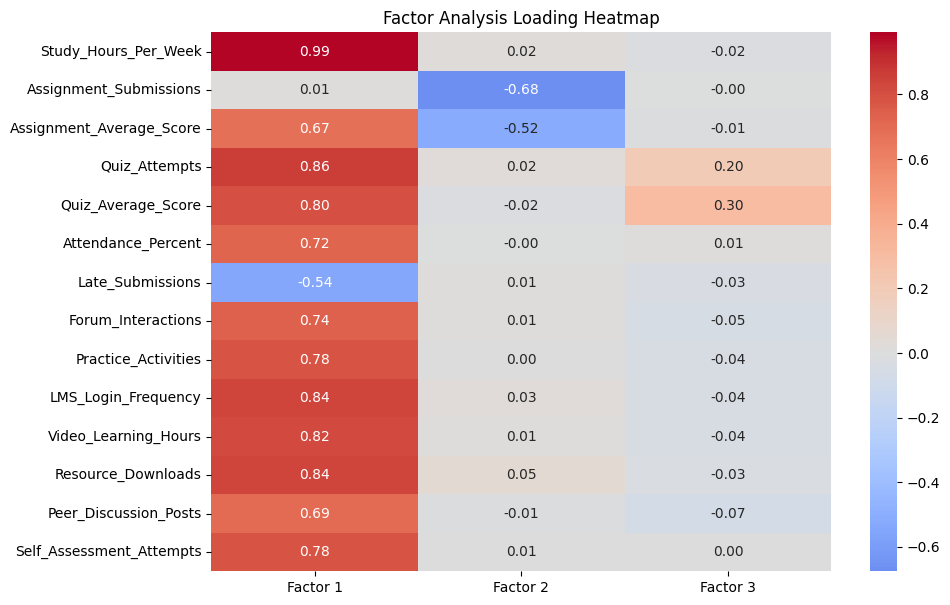

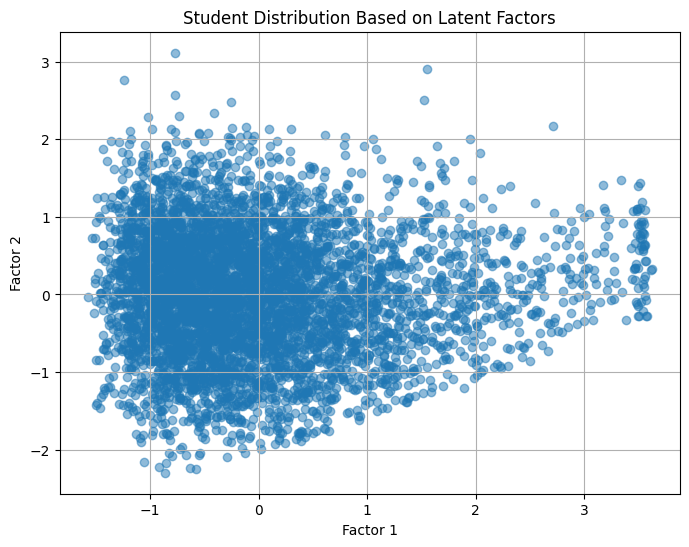

In [5]:

# ============================================================
# BLOCK 5: FACTOR ANALYSIS
# ============================================================

factor_results = []

for n_factors in [2, 3, 4, 5]:

    fa = FactorAnalysis(
        n_components=n_factors,
        max_iter=1000,
        tol=0.01,
        random_state=42
    )

    fa.fit(X_scaled)

    factor_results.append({
        'Number of Factors': n_factors,
        'Log Likelihood': fa.score(X_scaled),
        'Iterations': fa.n_iter_
    })

print("FACTOR ANALYSIS COMPARISON")
display(pd.DataFrame(factor_results))

# Final Factor Analysis model
fa_final = FactorAnalysis(
    n_components=3,
    max_iter=1000,
    tol=0.01,
    random_state=42
)

factor_scores = fa_final.fit_transform(X_scaled)

print("\nFactor Scores Shape:", factor_scores.shape)

# Display factor loadings
loadings = pd.DataFrame(
    fa_final.components_.T,
    index=X.columns,
    columns=['Factor 1', 'Factor 2', 'Factor 3']
)

print("\nFACTOR LOADINGS:")
display(loadings.round(3))

# Visualize factor loadings
plt.figure(figsize=(10, 7))

sns.heatmap(
    loadings,
    annot=True,
    cmap='coolwarm',
    center=0,
    fmt='.2f'
)

plt.title("Factor Analysis Loading Heatmap")
plt.show()

# Visualize student factor scores
plt.figure(figsize=(8, 6))

plt.scatter(
    factor_scores[:, 0],
    factor_scores[:, 1],
    alpha=0.5
)

plt.xlabel("Factor 1")
plt.ylabel("Factor 2")
plt.title("Student Distribution Based on Latent Factors")
plt.grid()
plt.show()

# ============================================================
# END: BLOCK 5
# ============================================================


PCA COMPONENT COMPARISON


,Components,Explained Variance,Information Lost
0,2,0.674578,0.325422
1,3,0.724525,0.275475
2,4,0.761678,0.238322
3,5,0.795929,0.204071
4,6,0.827948,0.172052
5,8,0.885109,0.114891
6,10,0.935535,0.064465



Original Data Shape: (5000, 14)
Reduced Data Shape: (5000, 3)

Explained Variance Ratio:
[0.58972757 0.0848506  0.0499472 ]

Total Explained Variance:
0.7245253670450741


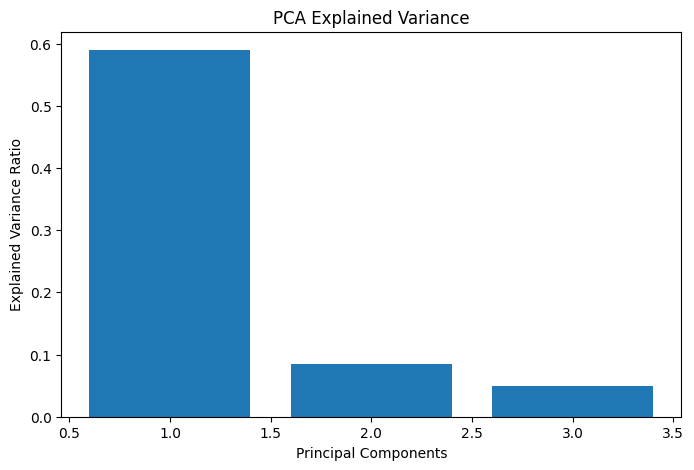

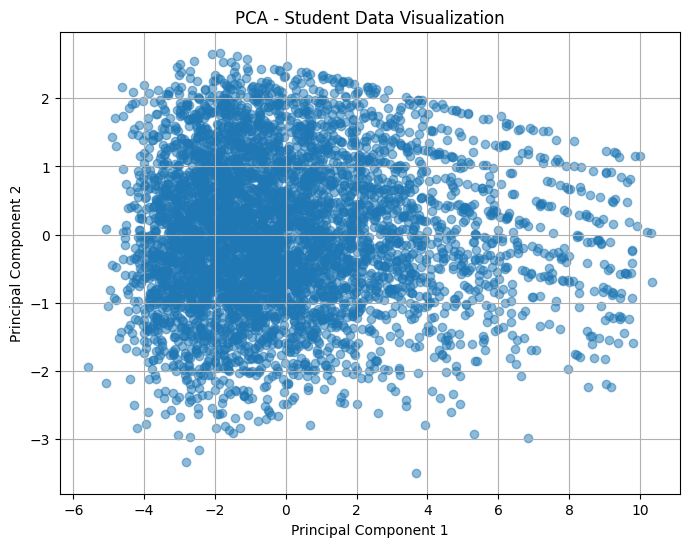


PCA COMPONENT LOADINGS:


,PC1,PC2,PC3
Study_Hours_Per_Week,0.340,-0.040,0.031
Assignment_Submissions,0.013,0.879,-0.001
Assignment_Average_Score,0.245,0.457,0.015
Quiz_Attempts,0.301,-0.048,0.061
Quiz_Average_Score,0.286,-0.024,0.033
Attendance_Percent,0.261,-0.037,0.040
Late_Submissions,-0.201,0.017,0.967
Forum_Interactions,0.265,-0.039,0.020
Practice_Activities,0.276,-0.027,0.063
LMS_Login_Frequency,0.295,-0.044,0.061


In [6]:

# ============================================================
# BLOCK 6: PRINCIPAL COMPONENT ANALYSIS (PCA)
# ============================================================

# Compare PCA with different component counts
pca_results = []

for n in [2, 3, 4, 5, 6, 8, 10]:

    pca_model = PCA(
        n_components=n,
        svd_solver='full',
        whiten=False
    )

    transformed = pca_model.fit_transform(X_scaled)

    pca_results.append({
        'Components': n,
        'Explained Variance': pca_model.explained_variance_ratio_.sum(),
        'Information Lost': 1 - pca_model.explained_variance_ratio_.sum()
    })

print("PCA COMPONENT COMPARISON")
display(pd.DataFrame(pca_results))

# Final PCA model with 3 components
pca_final = PCA(
    n_components=3,
    svd_solver='full',
    whiten=False
)

X_pca = pca_final.fit_transform(X_scaled)

print("\nOriginal Data Shape:", X_scaled.shape)
print("Reduced Data Shape:", X_pca.shape)

print("\nExplained Variance Ratio:")
print(pca_final.explained_variance_ratio_)

print("\nTotal Explained Variance:")
print(pca_final.explained_variance_ratio_.sum())

# Plot individual explained variance
plt.figure(figsize=(8, 5))

plt.bar(
    range(1, 4),
    pca_final.explained_variance_ratio_
)

plt.xlabel("Principal Components")
plt.ylabel("Explained Variance Ratio")
plt.title("PCA Explained Variance")
plt.show()

# PCA 2D visualization
plt.figure(figsize=(8, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    alpha=0.5
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA - Student Data Visualization")
plt.grid()
plt.show()

# PCA component loadings
pca_loadings = pd.DataFrame(
    pca_final.components_.T,
    index=X.columns,
    columns=['PC1', 'PC2', 'PC3']
)

print("\nPCA COMPONENT LOADINGS:")
display(pca_loadings.round(3))

# ============================================================
# END: BLOCK 6
# ============================================================


LATENT DIMENSION ANALYSIS


,Component,Individual Variance,Cumulative Variance
0,1,0.5897,0.5897
1,2,0.0849,0.6746
2,3,0.0499,0.7245
3,4,0.0372,0.7617
4,5,0.0343,0.7959
5,6,0.0320,0.8279
6,7,0.0290,0.8569
7,8,0.0282,0.8851
8,9,0.0257,0.9108
9,10,0.0248,0.9355


80% variance requires 6 components
85% variance requires 7 components
90% variance requires 9 components
95% variance requires 11 components
99% variance requires 13 components


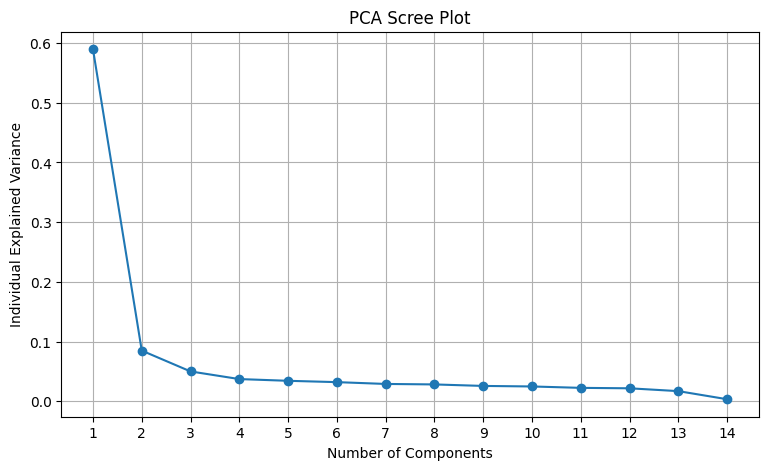

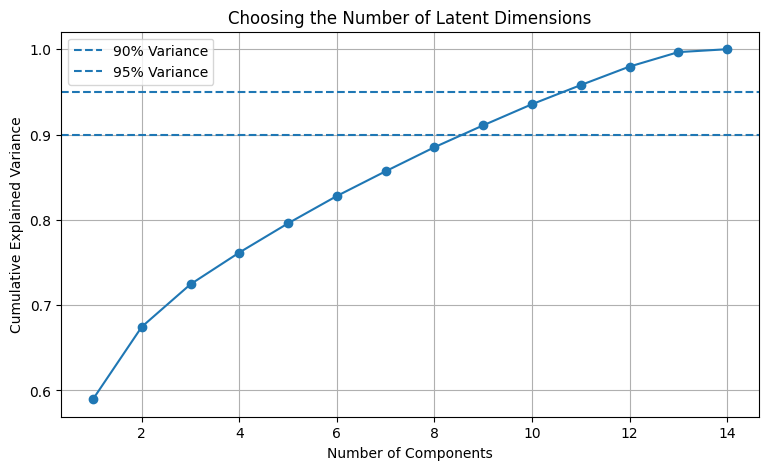


Recommended components for 90% variance: 9
Original Shape: (5000, 14)
Reduced Shape: (5000, 9)


In [7]:

# ============================================================
# BLOCK 7: CHOOSING NUMBER OF LATENT DIMENSIONS
# ============================================================

pca_all = PCA()
pca_all.fit(X_scaled)

explained_variance = pca_all.explained_variance_ratio_

cumulative_variance = np.cumsum(explained_variance)

# Display variance for each component
dimension_table = pd.DataFrame({
    'Component': range(1, len(explained_variance) + 1),
    'Individual Variance': explained_variance,
    'Cumulative Variance': cumulative_variance
})

print("LATENT DIMENSION ANALYSIS")
display(dimension_table.round(4))

# Find dimensions required for different variance thresholds
thresholds = [0.80, 0.85, 0.90, 0.95, 0.99]

for threshold in thresholds:

    dimensions = np.argmax(
        cumulative_variance >= threshold
    ) + 1

    print(
        f"{threshold*100:.0f}% variance requires "
        f"{dimensions} components"
    )

# Scree plot
plt.figure(figsize=(9, 5))

plt.plot(
    range(1, len(explained_variance) + 1),
    explained_variance,
    marker='o'
)

plt.xlabel("Number of Components")
plt.ylabel("Individual Explained Variance")
plt.title("PCA Scree Plot")
plt.xticks(range(1, len(explained_variance) + 1))
plt.grid()
plt.show()

# Cumulative variance graph
plt.figure(figsize=(9, 5))

plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker='o'
)

plt.axhline(
    y=0.90,
    linestyle='--',
    label='90% Variance'
)

plt.axhline(
    y=0.95,
    linestyle='--',
    label='95% Variance'
)

plt.xlabel("Number of Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("Choosing the Number of Latent Dimensions")
plt.legend()
plt.grid()
plt.show()

# Automatically select components for 90% variance
optimal_dimensions = np.argmax(
    cumulative_variance >= 0.90
) + 1

print("\nRecommended components for 90% variance:",
      optimal_dimensions)

# Transform data using selected dimensions
pca_optimal = PCA(n_components=optimal_dimensions)

X_optimal = pca_optimal.fit_transform(X_scaled)

print("Original Shape:", X_scaled.shape)
print("Reduced Shape:", X_optimal.shape)

# ============================================================
# END: BLOCK 7
# ============================================================


EUCLIDEAN DISTANCE:
[[0.    3.578 3.725 4.779 4.749]
 [3.578 0.    3.561 6.271 3.688]
 [3.725 3.561 0.    4.528 4.516]
 [4.779 6.271 4.528 0.    7.005]
 [4.749 3.688 4.516 7.005 0.   ]]

MANHATTAN DISTANCE:
[[ 0.    10.682 11.783 14.284 14.217]
 [10.682  0.    11.279 21.143 11.657]
 [11.783 11.279  0.    14.555 13.881]
 [14.284 21.143 14.555  0.    23.683]
 [14.217 11.657 13.881 23.683  0.   ]]

COSINE DISTANCE:
[[0.    1.074 0.798 0.555 1.503]
 [1.074 0.    0.987 1.366 1.311]
 [0.798 0.987 0.    0.477 1.287]
 [0.555 1.366 0.477 0.    1.513]
 [1.503 1.311 1.287 1.513 0.   ]]


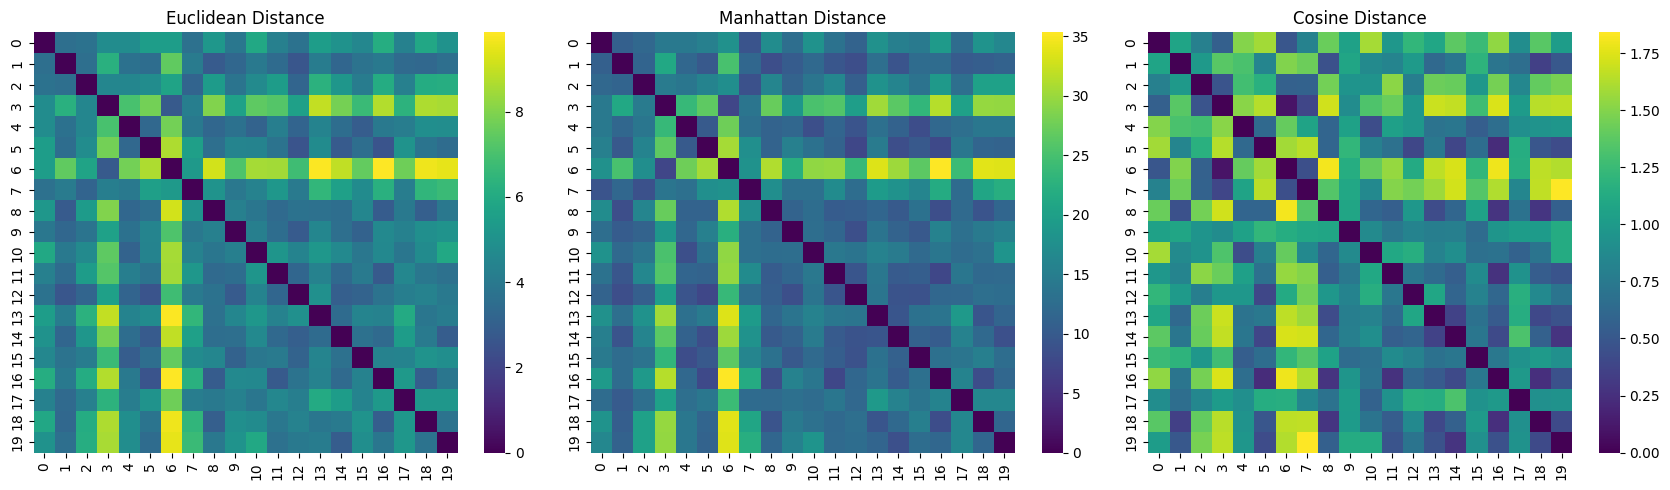


CLUSTER EVALUATION RESULTS:


,Clusters,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Score
0,2,0.3507,1.1143,3147.7897
1,3,0.2205,1.4479,2429.3924
2,4,0.1556,1.7645,1921.4208
3,5,0.1409,1.8843,1607.6406
4,6,0.1221,1.9255,1397.2560


In [8]:

# ============================================================
# BLOCK 8: MEASURING DISSIMILARITY AND EVALUATING CLUSTERS
# ============================================================

from sklearn.metrics import pairwise_distances

# Select first 100 students for distance calculations
sample_data = X_scaled[:100]

# Calculate distance matrices
euclidean = pairwise_distances(
    sample_data,
    metric='euclidean'
)

manhattan = pairwise_distances(
    sample_data,
    metric='manhattan'
)

cosine = pairwise_distances(
    sample_data,
    metric='cosine'
)

print("EUCLIDEAN DISTANCE:")
print(euclidean[:5, :5].round(3))

print("\nMANHATTAN DISTANCE:")
print(manhattan[:5, :5].round(3))

print("\nCOSINE DISTANCE:")
print(cosine[:5, :5].round(3))

# Visualize distance matrices
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

sns.heatmap(
    euclidean[:20, :20],
    ax=axes[0],
    cmap='viridis'
)
axes[0].set_title("Euclidean Distance")

sns.heatmap(
    manhattan[:20, :20],
    ax=axes[1],
    cmap='viridis'
)
axes[1].set_title("Manhattan Distance")

sns.heatmap(
    cosine[:20, :20],
    ax=axes[2],
    cmap='viridis'
)
axes[2].set_title("Cosine Distance")

plt.tight_layout()
plt.show()

# Evaluate clustering for different K values
evaluation_results = []

for k in [2, 3, 4, 5, 6]:

    model = KMeans(
        n_clusters=k,
        n_init=10,
        random_state=42
    )

    labels = model.fit_predict(X_scaled)

    evaluation_results.append({
        'Clusters': k,
        'Silhouette Score': silhouette_score(
            X_scaled, labels
        ),
        'Davies-Bouldin Index': davies_bouldin_score(
            X_scaled, labels
        ),
        'Calinski-Harabasz Score': calinski_harabasz_score(
            X_scaled, labels
        )
    })

evaluation_df = pd.DataFrame(evaluation_results)

print("\nCLUSTER EVALUATION RESULTS:")
display(evaluation_df.round(4))

# ============================================================
# END: BLOCK 8
# ============================================================


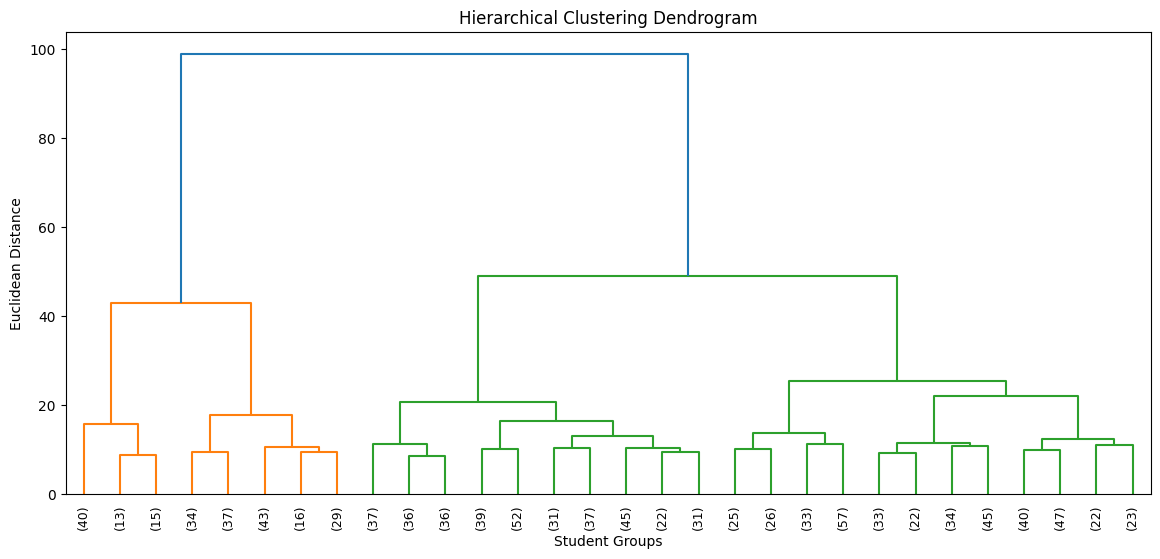

HIERARCHICAL CLUSTERING RESULTS


,Clusters,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Score
0,2,0.3408,1.1310,545.6541
1,3,0.1466,1.8350,392.2093
2,4,0.1373,1.7634,341.7745
3,5,0.1113,2.1184,281.0436



LINKAGE METHOD COMPARISON


,Linkage Method,Silhouette Score,Davies-Bouldin Index
0,ward,0.1466,1.8350
1,complete,0.2064,1.4368
2,average,0.2654,1.1868



Final Cluster Distribution:
0    227
1    407
2    366
Name: count, dtype: int64


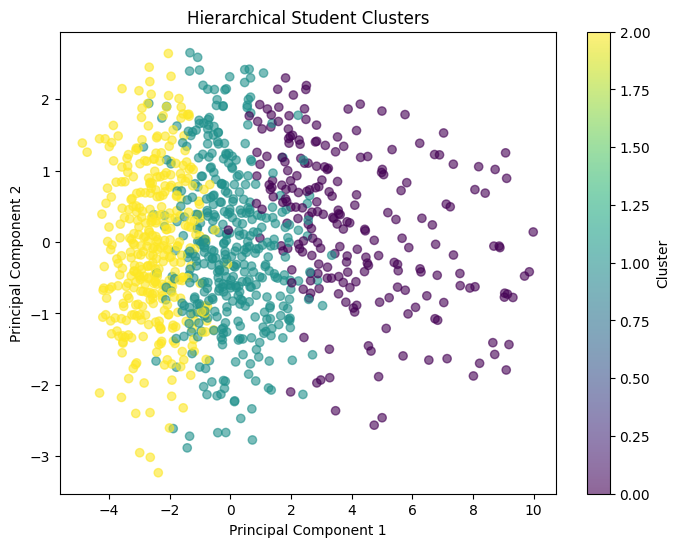

In [9]:

# ============================================================
# BLOCK 9: HIERARCHICAL CLUSTERING
# ============================================================

# Select a sample of 1000 students
np.random.seed(42)

sample_indices = np.random.choice(
    len(X_scaled),
    size=1000,
    replace=False
)

X_hier = X_scaled[sample_indices]

# ---------------- DENDROGRAM ----------------

# Ward linkage
Z = linkage(
    X_hier,
    method='ward',
    metric='euclidean'
)

plt.figure(figsize=(14, 6))

dendrogram(
    Z,
    truncate_mode='lastp',
    p=30,
    leaf_rotation=90,
    leaf_font_size=9
)

plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Student Groups")
plt.ylabel("Euclidean Distance")
plt.show()

# ---------------- DIFFERENT CLUSTER COUNTS ----------------

hier_results = []

for k in [2, 3, 4, 5]:

    model = AgglomerativeClustering(
        n_clusters=k,
        linkage='ward',
        metric='euclidean'
    )

    labels = model.fit_predict(X_hier)

    hier_results.append({
        'Clusters': k,
        'Silhouette Score': silhouette_score(
            X_hier, labels
        ),
        'Davies-Bouldin Index': davies_bouldin_score(
            X_hier, labels
        ),
        'Calinski-Harabasz Score': calinski_harabasz_score(
            X_hier, labels
        )
    })

print("HIERARCHICAL CLUSTERING RESULTS")
display(pd.DataFrame(hier_results).round(4))

# ---------------- LINKAGE COMPARISON ----------------

linkage_results = []

for method in ['ward', 'complete', 'average']:

    model = AgglomerativeClustering(
        n_clusters=3,
        linkage=method,
        metric='euclidean'
    )

    labels = model.fit_predict(X_hier)

    linkage_results.append({
        'Linkage Method': method,
        'Silhouette Score': silhouette_score(
            X_hier, labels
        ),
        'Davies-Bouldin Index': davies_bouldin_score(
            X_hier, labels
        )
    })

print("\nLINKAGE METHOD COMPARISON")
display(pd.DataFrame(linkage_results).round(4))

# ---------------- FINAL MODEL ----------------

hier_final = AgglomerativeClustering(
    n_clusters=3,
    linkage='ward',
    metric='euclidean'
)

hier_labels = hier_final.fit_predict(X_hier)

print("\nFinal Cluster Distribution:")
print(pd.Series(hier_labels).value_counts().sort_index())

# Visualize using PCA
X_hier_2d = PCA(n_components=2).fit_transform(X_hier)

plt.figure(figsize=(8, 6))

plt.scatter(
    X_hier_2d[:, 0],
    X_hier_2d[:, 1],
    c=hier_labels,
    cmap='viridis',
    alpha=0.6
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Hierarchical Student Clusters")
plt.colorbar(label="Cluster")
plt.show()

# ============================================================
# END: BLOCK 9
# ============================================================


FINAL MODEL COMPARISON


,Algorithm,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Score
0,K-Means,0.2292,1.4087,474.8797
1,Gaussian Mixture,0.1729,1.5194,361.0406
2,Hierarchical,0.1466,1.8350,392.2093


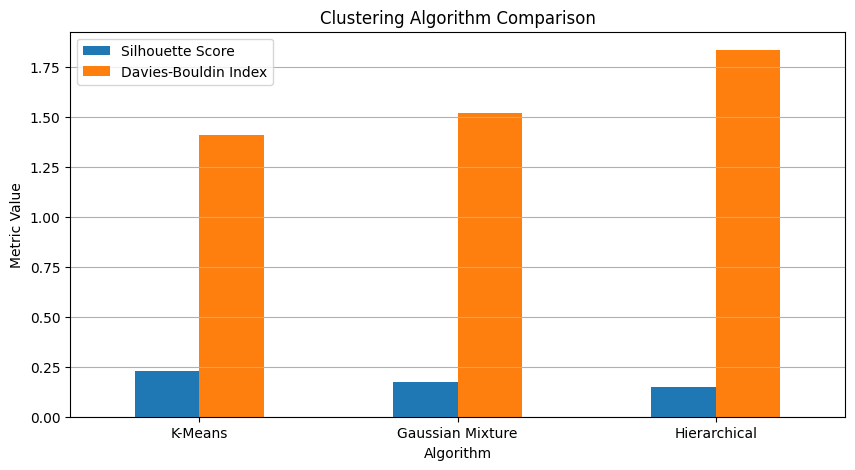


K-Means Distribution:
0    521
1    376
2    103
Name: count, dtype: int64

GMM Distribution:
0    446
1     79
2    475
Name: count, dtype: int64

Hierarchical Distribution:
0    227
1    407
2    366
Name: count, dtype: int64


In [10]:

# ============================================================
# BLOCK 10: FINAL CLUSTERING MODEL COMPARISON
# ============================================================

# Use the same sample for fair comparison
comparison_data = X_scaled[sample_indices]

# K-Means
km = KMeans(
    n_clusters=3,
    n_init=10,
    random_state=42
)

km_labels = km.fit_predict(comparison_data)

# GMM
gm = GaussianMixture(
    n_components=3,
    covariance_type='full',
    n_init=3,
    random_state=42
)

gm.fit(comparison_data)
gm_labels = gm.predict(comparison_data)

# Hierarchical
hc = AgglomerativeClustering(
    n_clusters=3,
    linkage='ward',
    metric='euclidean'
)

hc_labels = hc.fit_predict(comparison_data)

# Evaluate all models
models = {
    'K-Means': km_labels,
    'Gaussian Mixture': gm_labels,
    'Hierarchical': hc_labels
}

comparison_results = []

for name, labels in models.items():

    comparison_results.append({
        'Algorithm': name,
        'Silhouette Score': silhouette_score(
            comparison_data, labels
        ),
        'Davies-Bouldin Index': davies_bouldin_score(
            comparison_data, labels
        ),
        'Calinski-Harabasz Score': calinski_harabasz_score(
            comparison_data, labels
        )
    })

comparison_df = pd.DataFrame(comparison_results)

print("FINAL MODEL COMPARISON")
display(comparison_df.round(4))

# Comparison chart
comparison_df.set_index('Algorithm')[
    ['Silhouette Score', 'Davies-Bouldin Index']
].plot(
    kind='bar',
    figsize=(10, 5)
)

plt.title("Clustering Algorithm Comparison")
plt.ylabel("Metric Value")
plt.xticks(rotation=0)
plt.grid(axis='y')
plt.show()

# Cluster distributions
print("\nK-Means Distribution:")
print(pd.Series(km_labels).value_counts().sort_index())

print("\nGMM Distribution:")
print(pd.Series(gm_labels).value_counts().sort_index())

print("\nHierarchical Distribution:")
print(pd.Series(hc_labels).value_counts().sort_index())

# ============================================================
# END: BLOCK 10
# ============================================================
